Step 1: Loading Breast Cancer dataset...
Dataset loaded successfully!
Features: (569, 30)
Labels: (569,)
Classes: ['malignant' 'benign']

Step 2: Splitting dataset...
Training samples: 398
Testing samples: 171

Step 3: Standardizing features...
Feature scaling completed!

Step 4: Defining hyperparameters...
C values: [0.1, 1, 10, 100]
Gamma values: [1, 0.1, 0.01, 0.001]
Kernels: ['rbf', 'linear']

Step 5: Starting Grid Search with 5-fold CV...
Grid Search completed!
Best parameters: {'C': 10, 'gamma': 0.001, 'kernel': 'rbf'}
Best CV accuracy: 0.9799

Step 6: Evaluating the best model...
Test accuracy: 0.9708

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.94      0.96        64
      benign       0.96      0.99      0.98       107

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171


Step 7: Displaying confusion mat

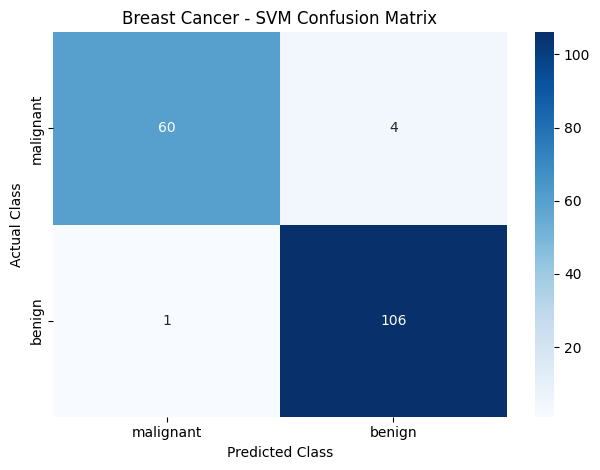


Step 8: Displaying top 5 Grid Search results...
    param_C  param_gamma param_kernel  mean_test_score  rank_test_score
22     10.0        0.001          rbf         0.979905                1
1       0.1        1.000       linear         0.977405                2
7       0.1        0.001       linear         0.977405                2
3       0.1        0.100       linear         0.977405                2
5       0.1        0.010       linear         0.977405                2

Step 9: Starting 5-fold cross-validation...
Accuracy for each fold: [0.95       1.         0.975      0.97468354 0.93670886]
Mean accuracy: 0.9673
Standard deviation: 0.022

Step 10: Plotting cross-validation results...


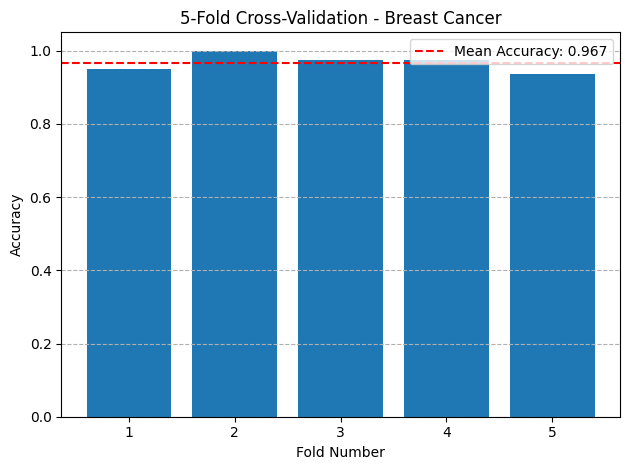


Experiment completed successfully!
Grid Search identifies suitable hyperparameters.
Cross-validation evaluates model consistency.
The SVM model classifies tumors as benign or malignant.


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load Dataset
print("Step 1: Loading Breast Cancer dataset...")

data = load_breast_cancer()
X = data.data
y = data.target

print("Dataset loaded successfully!")
print("Features:", X.shape)
print("Labels:", y.shape)
print("Classes:", data.target_names)

# 2. Split Dataset
print("\nStep 2: Splitting dataset...")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# 3. Standardize Features
print("\nStep 3: Standardizing features...")

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed!")

# 4. Define Hyperparameter Grid
print("\nStep 4: Defining hyperparameters...")

params = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf', 'linear']
}

print("C values:", params['C'])
print("Gamma values:", params['gamma'])
print("Kernels:", params['kernel'])

# 5. Perform Grid Search
print("\nStep 5: Starting Grid Search with 5-fold CV...")

grid = GridSearchCV(
    SVC(),
    params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Grid Search completed!")
print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))

# 6. Evaluate Best Model
print("\nStep 6: Evaluating the best model...")

model = grid.best_estimator_
y_pred = model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

# 7. Confusion Matrix
print("\nStep 7: Displaying confusion matrix...")

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Breast Cancer - SVM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# 8. Display Top Grid Search Results
print("\nStep 8: Displaying top 5 Grid Search results...")

results = pd.DataFrame(grid.cv_results_)

print(
    results[
        ['param_C', 'param_gamma', 'param_kernel',
         'mean_test_score', 'rank_test_score']
    ].sort_values('rank_test_score').head()
)

# 9. Perform K-Fold Cross-Validation
print("\nStep 9: Starting 5-fold cross-validation...")

k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    SVC(),
    X_train,
    y_train,
    cv=kf,
    scoring='accuracy'
)

print("Accuracy for each fold:", cv_scores)
print("Mean accuracy:", round(np.mean(cv_scores), 4))
print("Standard deviation:", round(np.std(cv_scores), 4))

# 10. Plot Cross-Validation Scores
print("\nStep 10: Plotting cross-validation results...")

plt.bar(range(1, k + 1), cv_scores)
plt.axhline(
    np.mean(cv_scores),
    color='red',
    linestyle='--',
    label=f'Mean Accuracy: {np.mean(cv_scores):.3f}'
)

plt.title("5-Fold Cross-Validation - Breast Cancer")
plt.xlabel("Fold Number")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

# 11. Conclusion
print("\nExperiment completed successfully!")
print("Grid Search identifies suitable hyperparameters.")
print("Cross-validation evaluates model consistency.")
print("The SVM model classifies tumors as benign or malignant.")